# 02 Logistic regression

L1- or L2-penalized logistic regression on all 32 features (nominal features one-hot encoded).
Penalty and C are tuned by 5-fold CV inside each outer fold (see `common.nested_cv`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline

from common import (FIGURES_DIR, INNER_CV, RESULTS_DIR, SEED, load_train, make_preprocessor,
                    nested_cv, save_results, summarize, write_submission)

X, y = load_train()
X.shape

(1504, 32)

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

from common import CONTINUOUS, FEATURES, NOMINAL


def make_search(features=FEATURES):
    pipe = Pipeline([("prep", make_preprocessor(features)),
                     ("clf", LogisticRegression(solver="liblinear", max_iter=1000, random_state=SEED))])
    grid = {"clf__l1_ratio": [0.0, 1.0], "clf__C": np.logspace(-2, 2, 25)}  # l1_ratio 1 = L1 (lasso), 0 = L2 (ridge)
    return GridSearchCV(pipe, grid, scoring="accuracy", cv=INNER_CV, n_jobs=-1)

## Nested cross-validation

In [3]:
folds, oof, params = nested_cv(make_search(), X, y)
save_results("logistic_regression", folds, oof, params)
print(params.to_string(index=False))
summarize(folds)

 fold   clf__C  clf__l1_ratio
    0 0.464159            1.0
    1 0.316228            1.0
    2 0.316228            1.0
    3 0.215443            1.0
    4 0.681292            1.0


accuracy         precision          recall         specificity  \
                 mean     std      mean     std    mean     std        mean   
rule                                                                          
0.5            0.8331  0.0233    0.7960  0.0304  0.7105  0.0629      0.9002   
recall>=0.90   0.7779  0.0294    0.6327  0.0352  0.8928  0.0247      0.7151   

                         fpr             fnr              f1             auc  \
                 std    mean     std    mean     std    mean     std    mean   
rule                                                                           
0.5           0.0183  0.0998  0.0183  0.2895  0.0629  0.7497  0.0416  0.8969   
recall>=0.90  0.0385  0.2849  0.0385  0.1072  0.0247  0.7403  0.0296  0.8969   

                      
                 std  
rule                  
0.5           0.0221  
recall>=0.90  0.0221

## Ablation: the 2024 feature set

The 2024 notebook used only the 15 continuous features plus the one-hot nominal features, silently
dropping all 15 binary features. Same protocol, that feature set:

In [4]:
folds_old, oof_old, params_old = nested_cv(make_search(CONTINUOUS + NOMINAL), X, y)
save_results("logistic_regression_2024_features", folds_old, oof_old, params_old)
summarize(folds_old)

accuracy         precision          recall         specificity  \
                 mean     std      mean     std    mean     std        mean   
rule                                                                          
0.5            0.7719  0.0256    0.7320  0.0695  0.5695  0.0370      0.8828   
recall>=0.90   0.5977  0.0232    0.4649  0.0162  0.8966  0.0455      0.4343   

                         fpr             fnr              f1             auc  \
                 std    mean     std    mean     std    mean     std    mean   
rule                                                                           
0.5           0.0423  0.1172  0.0423  0.4305  0.0370  0.6388  0.0335  0.8164   
recall>=0.90  0.0465  0.5657  0.0465  0.1034  0.0455  0.6119  0.0170  0.8164   

                      
                 std  
rule                  
0.5           0.0345  
recall>=0.90  0.0345

## Final model and coefficients

Refit the search on all 1,504 rows. Coefficients are log-odds changes over the full range of a
continuous feature (features are min-max scaled), or for a binary/one-hot indicator switching 0 → 1.

chosen: {'clf__C': np.float64(0.46415888336127775), 'clf__l1_ratio': 1.0} | inner CV accuracy 0.8345


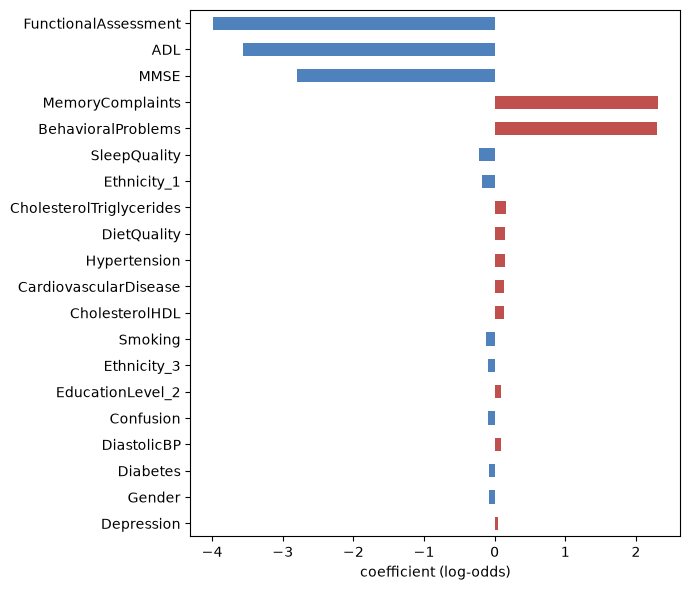

non-zero coefficients: 28 of 36


In [5]:
final = make_search().fit(X, y)
print("chosen:", final.best_params_, f"| inner CV accuracy {final.best_score_:.4f}")
clf, prep = final.best_estimator_["clf"], final.best_estimator_["prep"]
coef = pd.Series(clf.coef_[0], index=prep.get_feature_names_out()).sort_values(key=np.abs, ascending=False)
coef.to_csv(RESULTS_DIR / "logistic_regression_coefficients.csv", header=["coef"])

shown = coef[coef != 0].iloc[:20].iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 6))
shown.plot.barh(ax=ax, color=np.where(shown > 0, "#c0504d", "#4f81bd"))
ax.set_xlabel("coefficient (log-odds)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "lr_coefficients.png", dpi=150)
plt.show()
print("non-zero coefficients:", int((coef != 0).sum()), "of", len(coef))

In [6]:
write_submission("logistic_regression", final)

PosixPath('submissions/logistic_regression.csv')